In [1]:
import scanpy as sc
import scanpy.external as sce

import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns
import scipy.sparse as sp
import anndata as ad

from copy import deepcopy

# sc.logging.print_version()
sc.settings.verbosity = 3
sc.set_figure_params(figsize=(5,5))

import sys
from pathlib import Path

_start = Path.cwd().resolve()
_repo_root = next((p for p in [_start, *_start.parents] if (p / "chronopack").exists()), _start)
if str(_repo_root) not in sys.path:
    sys.path.insert(0, str(_repo_root))

import chronopack as cp


# Create AnnData object

In [2]:
sample_paths = [
    '../input/N701_scK562_TNFA_Replication_RT_1.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    '../input/N702_scK562_TNFA_Replication_RT_2.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    '../input/N703_scK562_TNFA_Replication_RT_3.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
    '../input/N704_scK562_TNFA_Replication_RT_4.aligned.sorted.merged.tagged.dge.time_tags.csv.gz',
]

adata = cp.io.read_time_tagged_dge(sample_paths, sample_names=['N701', 'N702', 'N703', 'N704'])
print(adata)


AnnData object with n_obs × n_vars = 7646 × 27942
    obs: 'COUNTS', 'sample', 'time', 'time_group'
    uns: 'chronopack'


/new-stg/home/alex/miniconda3/envs/chronopack-manuscript-20260919/lib/python3.13/site-packages/anndata/utils.py:311: UserWarning: X converted to numpy array with dtype float64
  warnings.warn(f"{name} converted to numpy array with dtype {arr.dtype}")


# QC & preprocessing

AnnData object with n_obs × n_vars = 7164 × 20036
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'chronopack'


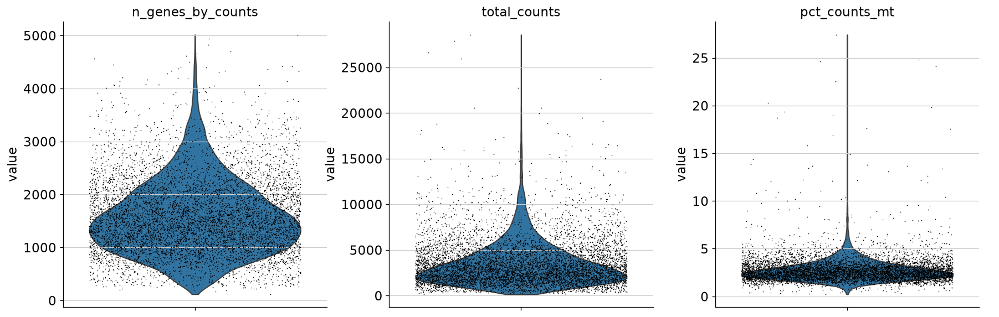

In [3]:
cp.io.annotate_qc_metrics(adata)
sc.pl.violin(adata, ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'], jitter=0.4, multi_panel=True)

adata = cp.io.filter_cells_by_qc(adata, min_counts=500, max_counts=15000, max_pct_mt=5, min_genes=500)
sc.pp.filter_genes(adata, min_cells=3)
print(adata)


In [4]:
sc.pp.scrublet(adata, batch_key="sample")
adata = adata[~adata.obs['predicted_doublet'], :]


# Standard processing

In [5]:
cell_cycle_genes = [x.strip() for x in open('/new-stg/home/alex/ref/gene_sets/regev_lab_cell_cycle_genes.txt')]
s_genes = cell_cycle_genes[:43]
g2m_genes = cell_cycle_genes[43:]
cell_cycle_genes = [x for x in cell_cycle_genes if x in adata.var_names]


In [6]:
cp.io.initialize_expression_layers(adata, target_sum=1e4)

sc.pp.highly_variable_genes(adata, batch_key='sample', n_top_genes=3000)
sc.tl.score_genes_cell_cycle(adata, s_genes=s_genes, g2m_genes=g2m_genes)
adata_hvg = adata[:, adata.var.highly_variable]
bck = adata_hvg.copy()


/new-stg/home/alex/tmp/ChronoPack/src/chronopack/io/_preprocessing.py:296: ImplicitModificationWarning: Setting element `.layers['counts']` of view, initializing view as actual.
  out.layers[counts_layer] = out.X.copy()


/new-stg/home/alex/miniconda3/envs/chronopack-manuscript-20260919/lib/python3.13/site-packages/anndata/_core/anndata.py:1138: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/new-stg/home/alex/tmp/ChronoPack/verification_runs/manuscript_full_pipeline_20260919_165539/k562-tnfa.hg38.rep/notebooks/PreprocessDatasets.ipynb:cell-10:8: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.


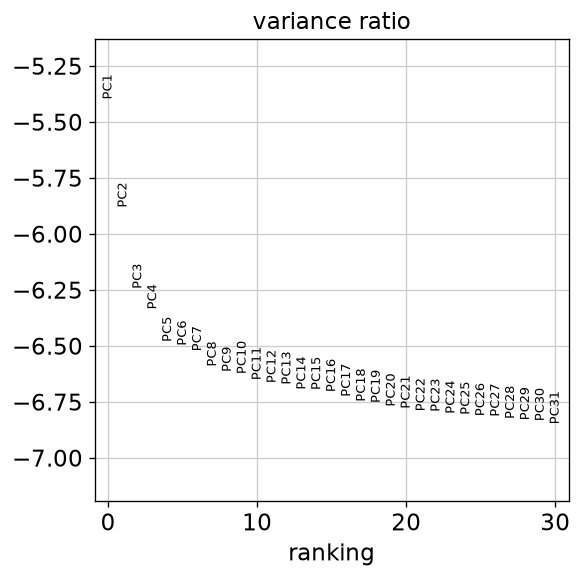

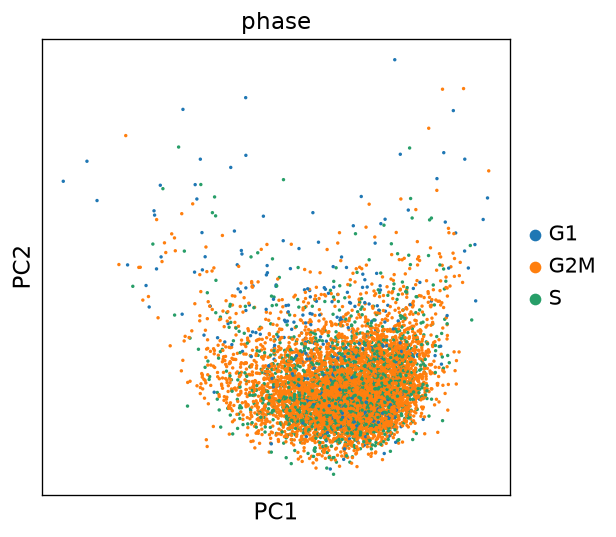

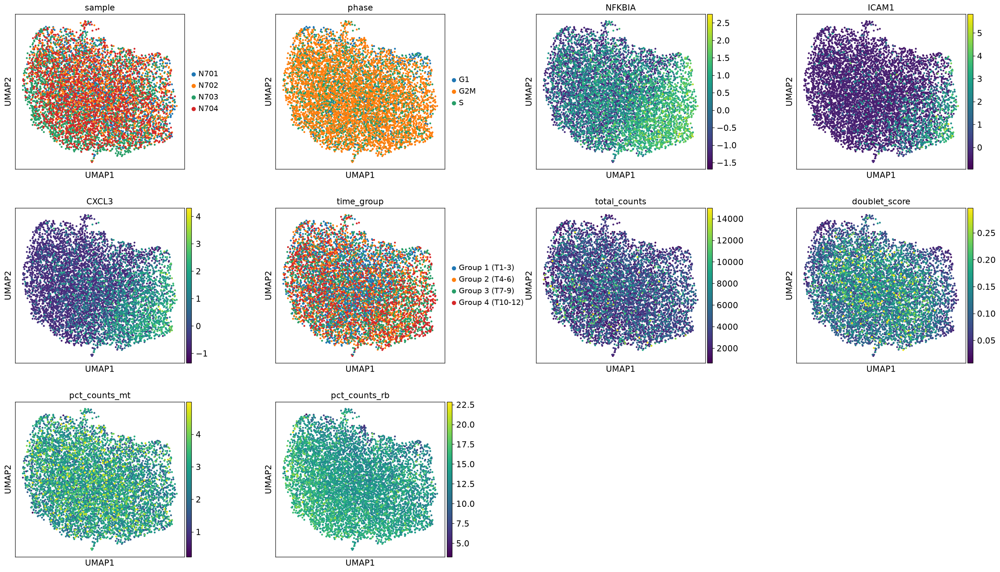

In [7]:
sc.pp.regress_out(adata_hvg, ['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score'])
sc.pp.scale(adata_hvg)
sc.tl.pca(adata_hvg, n_comps=50, svd_solver='arpack')
sc.pl.pca_variance_ratio(adata_hvg, n_pcs=30, log=True)
sc.pp.neighbors(adata_hvg, n_pcs=12)

sc.tl.umap(adata_hvg)
sc.tl.leiden(adata_hvg, resolution=0.1, key_added='leiden_unintegrated')

sc.pl.pca_scatter(adata_hvg, color='phase')
sc.pl.umap(adata_hvg, color=['sample', 'phase', 'NFKBIA', 'ICAM1', 'CXCL3', 'time_group', 'total_counts', 'doublet_score', 'pct_counts_mt', 'pct_counts_rb'], wspace=0.4, size=40, ncols=4)


# Batch effect correction w/ComBat

In [8]:
df = adata.obs[['time', 'sample']]
table = pd.crosstab(df['time'], df['sample'])
print(table)


sample  N701  N702  N703  N704
time                          
1        189   157   164   166
2        199   180   174   148
3        131   112   113   126
4        139   163   139   152
5        134    93   127   108
6        100   113    98   106
7        201   190   215   190
8        165   166   165   143
9        136   130   123   129
10       152   176   162   131
11       134   142   172   166
12       166   146   145   155


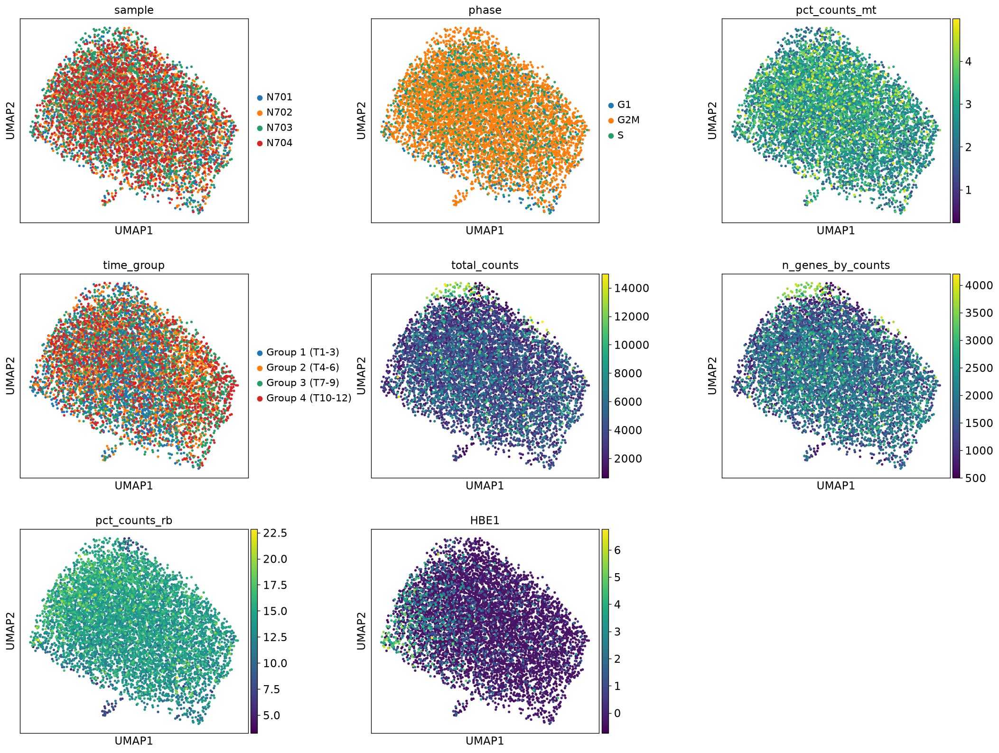

In [9]:
adata_hvg = bck.copy()

sc.pp.regress_out(adata_hvg, keys=['total_counts', 'pct_counts_mt', 'S_score', 'G2M_score']) # Remove QC + cell-cycle effects first
sc.pp.combat(adata_hvg, key='sample') # Batch correction on (log1p + residual) expression
adata_hvg.layers['corrected'] = adata_hvg.X.copy()

sc.pp.scale(adata_hvg, max_value=10)
sc.tl.pca(adata_hvg, n_comps=50)
sc.pp.neighbors(adata_hvg, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_hvg)
sc.pl.umap(adata_hvg, color=['sample', 'phase', 'pct_counts_mt', 'time_group', 'total_counts', 'n_genes_by_counts', 'pct_counts_rb', 'HBE1'], wspace=0.4, size=40, ncols=3)


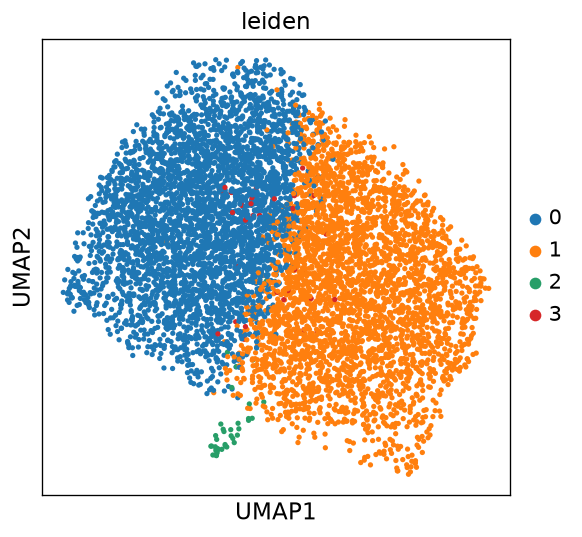

In [10]:
sc.tl.leiden(adata_hvg, resolution=0.5)
sc.pl.umap(adata_hvg, color=['leiden'], wspace=0.4, size=40, ncols=3)


Next, we'll iteratively remove clusters corresponding to low-quality cells

In [ ]:
# Maintained-environment variant: the manuscript's Leiden cluster removals are
# applied by barcode so the retained cells do not depend on the Leiden
# implementation (leidenalg 0.10.2 and 0.12.0 partition this graph differently).
# The list reproduces the manuscript's `leiden != '2'` (resolution 0.5) and
# `leiden != '6'` (resolution 1.0) removals.
manuscript_exclusions = pd.read_csv('exclude_leiden_clusters.manuscript.csv')

def drop_manuscript_cluster(adata_hvg, removed_at):
    excluded = pd.Index(manuscript_exclusions.loc[manuscript_exclusions['removed_at'] == removed_at, 'cell_id'])
    missing = excluded.difference(adata_hvg.obs_names)
    if len(missing):
        raise ValueError(f'{len(missing)} {removed_at} barcodes are not in adata_hvg')
    return adata_hvg[~adata_hvg.obs_names.isin(excluded), :]

adata_hvg = drop_manuscript_cluster(adata_hvg, 'leiden_r0.5_cluster2')
sc.tl.leiden(adata_hvg, resolution=0.7)
sc.pl.umap(adata_hvg, color=['leiden'], wspace=0.4, size=40, ncols=3)


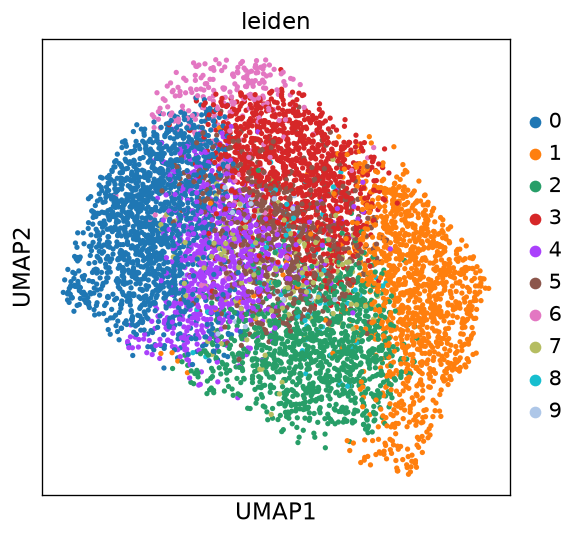

In [12]:
sc.tl.leiden(adata_hvg, resolution=1.0)
sc.pl.umap(adata_hvg, color=['leiden'], wspace=0.4, size=40, ncols=3)


In [ ]:
adata_hvg = drop_manuscript_cluster(adata_hvg, 'leiden_r1.0_cluster6')
sc.tl.leiden(adata_hvg, resolution=0.7)
sc.pl.umap(adata_hvg, color=['leiden'], wspace=0.4, size=40, ncols=3)


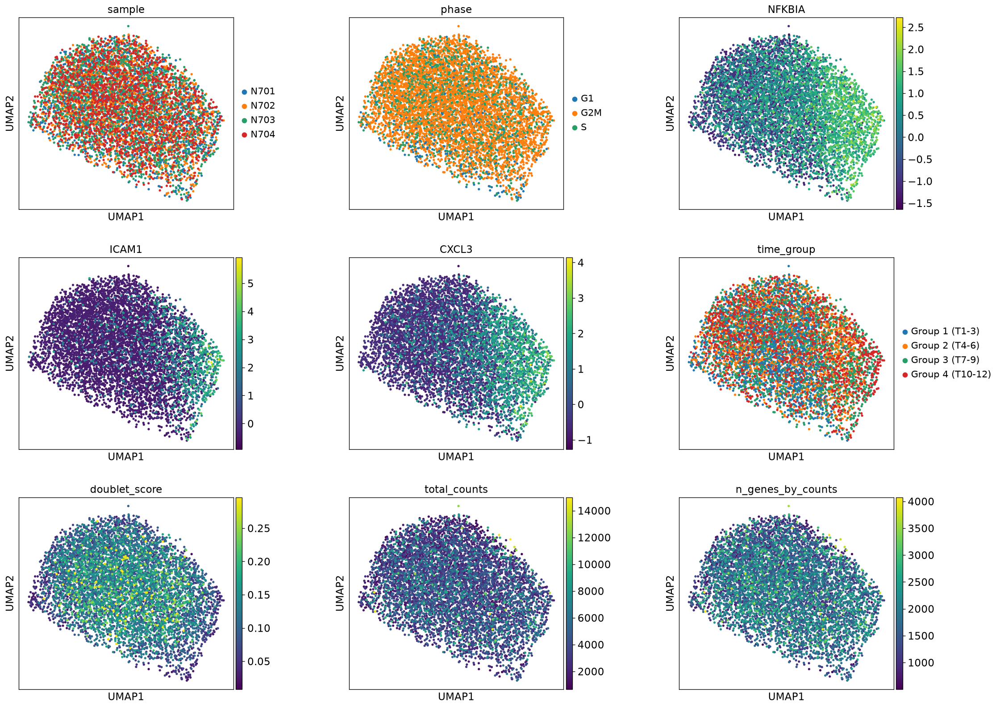

In [14]:
sc.pl.umap(adata_hvg, color=['sample', 'phase', 'NFKBIA', 'ICAM1', 'CXCL3', 'time_group', 'doublet_score', 'total_counts', 'n_genes_by_counts'], wspace=0.4, size=40, ncols=3)


# Save single-cell AnnData object

In [15]:
adata = adata[adata_hvg.obs.index, :]
adata.obsp = adata_hvg.obsp.copy()
adata.obsm = adata_hvg.obsm.copy()
adata.obs = adata_hvg.obs.copy()

print(adata)
print(adata_hvg)

cp.io.validate_preprocessed_adata(
    adata,
    require_layers=("counts", "cpm", "log1p"),
    require_qc=True,
    require_sample=True,
    require_time_group=True,
)
cp.io.validate_preprocessed_adata(
    adata_hvg,
    require_layers=("counts", "cpm", "log1p"),
    require_qc=True,
    require_sample=True,
    require_time_group=True,
)

adata.write_h5ad('../output/adata_full.1e4-variant.chk0.h5ad')
adata_hvg.write_h5ad('../output/adata_hvg.1e4-variant.chk0.h5ad')


AnnData object with n_obs × n_vars = 6857 × 20036
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_genes', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden'
    var: 'mt', 'rb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'chronopack', 'scrublet', 'log1p', 'hvg'
    obsm: 'X_pca', 'X_umap'
    layers: 'counts', 'cpm', 'log1p'
    obsp: 'distances', 'connectivities'
AnnData object with n_obs × n_vars = 6857 × 3000
    obs: 'COUNTS', 'sample', 'time', 'time_group', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_rb', 'pct_counts_rb', 'n_genes', 'doublet_score', 'predicted_doublet', 'S_score', 'G2M_score', 'phase', 'leiden'
    var: 'mt'